In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

from _path import NB_DIR
import sys
import os
from datetime import datetime
import pickle
import dill
import random
from typing import Optional

sys.path.append(str(NB_DIR))

import torch

from botorch.optim import optimize_acqf
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.acquisition.monte_carlo import qExpectedImprovement
from botorch.acquisition.objective import ConstrainedMCObjective, LinearMCObjective
from botorch.models import ModelListGP, SingleTaskGP
from botorch import fit_gpytorch_mll
from gpytorch.mlls.sum_marginal_log_likelihood import SumMarginalLogLikelihood

from matal.utils import load_cache
from matal.configs import DATA_DIR
from matal.utils.datatype import to_torch
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from matal.recipe import UniformCompositionGenerator, get_rand_comp
from matal.utils import auto_log, get_sid, obj_to_hash, merge_update, Bunch, cache_return, load_cache, save_cache
from matal.configs import BATCH_DIR, PROJ_CODE, MODEL_DIR, DATA_DIR
from matal.robot.ot2 import OT2ProcGeneratorV7

try:
    from sklearn.utils._testing import ignore_warnings
except ImportError:
    from sklearn.utils.testing import ignore_warnings

INFO:numexpr.utils:NumExpr defaulting to 8 threads.


## 0. Load SVM models

In [2]:
svm_models = load_cache('svm_models_v8')
display(svm_models)

X_COLS = ['cons_ZnCl2', 'cons_ZnOTF2', 'ratio_MeOH']
X_LIMS = np.array([35.0, 6.0, 1.0])

from matal.vis import marching_cubes, skimg_tri_to_poly, poly_to_skimg_tri, smooth_pvs_poly, get_mesh_pred

margin = 0.05
n_points = 331
pred_sol, grid_space, flattened = get_mesh_pred(svm_models['solubility'], margin=margin, n_points=n_points, target='pred')
pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=margin, n_points=n_points, target='pred', margin_value=-5.0)
pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=margin, n_points=n_points, target='pred', margin_value= 5.0)

# Value cutoff 
oer_cutoff = 1.74
her_cutoff = -0.86

merge_pred = ((pred_sol >= 0.5) & (pred_oer >= oer_cutoff) & (pred_her >= her_cutoff)).astype(np.float16)
verts, faces, *_ = marching_cubes(merge_pred, 0.5, spacing=(grid_space, ) * 3, gradient_direction='ascent', allow_degenerate=False)
verts -= margin

# Smooth iso-plane
poly = skimg_tri_to_poly(verts, faces)
smooth_poly = smooth_pvs_poly(poly, sm_iters=500, sm_rlx=0.2, sm2_iters=50, sm2_rlx=0.05, dp_factor=0.95, dp_angle=120, dp_iters=100)
smooth_verts, smooth_faces = poly_to_skimg_tri(smooth_poly)
print(f'Num of edge points:', len(smooth_verts))

# Precalculated kDTree for fast distance computation
import scipy
kdtree = scipy.spatial.KDTree(smooth_verts)

## Low res version for plotting GP model output
_n_points = 51
_pred_sol, _, _flattened = get_mesh_pred(svm_models['solubility'], margin=0, n_points=_n_points, target='pred')
_pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=0, n_points=_n_points, target='pred', margin_value=-5.0)
_pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=0, n_points=_n_points, target='pred', margin_value= 5.0)
_mask = (_pred_sol >= 0.5) & (_pred_oer >= oer_cutoff) & (_pred_her >= her_cutoff)
low_res_X = _flattened[_mask.reshape(-1)].astype(np.float64)
del _n_points, _pred_sol, _flattened, _pred_her, _mask
low_res_X

{'solubility': SVC(C=859.5792940061186, gamma=3.4589836312369657, probability=True,
     random_state=0),
 'HER': SVR(C=6.242440709438059, epsilon=0.004211530744928162, gamma=0.6547642454463255),
 'OER': SVR(C=2.8195945113291416, epsilon=7.409655120425588e-05,
     gamma=2.589799492724016)}

Num of edge points: 18273


array([[0.        , 0.36000001, 0.98000002],
       [0.        , 0.36000001, 1.        ],
       [0.        , 0.38      , 0.92000002],
       ...,
       [0.83999997, 0.        , 0.31999999],
       [0.83999997, 0.        , 0.34      ],
       [0.86000001, 0.        , 0.18000001]])

## 1. Train Gaussian Process models for CE and conductivity 

#### Scale CE using a custom ce_log() function to focus on changes >99%

> https://www.desmos.com/calculator/z0so28skga 


In [3]:
# baseline value when CE = 99%. Choose a baseline value = 2 to make the function always positive within [0, 100)
CE_LOG_BASELINE = 2

def ce_log(x):
    return CE_LOG_BASELINE - np.log10(100 - x)

def inv_ce_log(x):
    return 100 - np.power(10, CE_LOG_BASELINE - x)

_x = np.linspace(0, 100, num=1000000, endpoint=False)
assert np.allclose(_x, inv_ce_log(ce_log(_x)))
del _x

In [4]:
pd.concat([
    pd.read_excel(DATA_DIR / 'Round 1.xlsx'),
    pd.read_excel(DATA_DIR / 'Round 2.xlsx', na_values='>>100')
], ignore_index=True)

,sample_sid,cons_ZnCl2(m),cons_ZnOTF2(m),ratio_MeOH(wt%),Conductivity(mS/cm),CE-1(%),CE-2(%),CE-3(%)
0,aES-0101,11.7400,0.2300,0.1000,71.157495,71.671627,77.812500,78.358135
1,aES-0102,3.8000,1.8000,0.0900,92.501233,66.319444,67.926587,NaN
2,aES-0103,1.6600,2.4200,0.4100,57.515337,65.853175,64.970238,64.523810
3,aES-0104,25.1600,0.1600,0.1600,14.958117,85.163690,91.299603,88.194444
4,aES-0105,4.9100,0.2200,0.7600,32.084189,72.435516,74.866071,70.838294
5,aES-0106,17.0200,0.9300,0.8900,2.797464,97.896825,97.529762,98.888889
6,aES-0107,1.2900,3.6400,0.7200,18.098456,72.781500,75.380800,70.946700
7,aES-0108,11.2200,0.1300,0.4500,33.998187,75.322421,73.878968,74.454365
8,aES-0109,23.9600,0.1800,0.5900,4.837212,95.347222,93.526786,95.099206
9,aES-010A,1.9100,2.0600,0.9500,20.491803,86.443452,90.109127,94.186508


In [5]:
def get_date():
    data_df = pd.concat([
        pd.read_excel(DATA_DIR / 'Round 1.xlsx'),
        pd.read_excel(DATA_DIR / 'Round 2.xlsx', na_values='>>100')
    ], ignore_index=True)
    CE_COLS = ['CE-1(%)', 'CE-2(%)', 'CE-3(%)']
    TOPTWO_CE_COLS = ['CE-T1(%)', 'CE-T2(%)', ]
    LOG_TOPTWO_CE_COLS = ['LgCE-T1(-)', 'LgCE-T2(-)', ]

    data_df[TOPTWO_CE_COLS] = data_df[CE_COLS].fillna(0).apply(lambda x: np.sort(x)[::-1][:2], axis=1,
                                                               result_type='expand')
    data_df['CE-T2(%)'] = data_df[TOPTWO_CE_COLS].apply(lambda x: x[0] if x[1] == 0.0 else x[1], axis=1)
    data_df[LOG_TOPTWO_CE_COLS] = ce_log(data_df[TOPTWO_CE_COLS])

    data_df['LgCE_Mean'] = data_df[LOG_TOPTWO_CE_COLS].mean(axis=1)
    data_df['LgCE_Var'] = np.clip(data_df[LOG_TOPTWO_CE_COLS].var(axis=1, ddof=0), 1e-4, None)
    data_df['Conductivity_Mean'] = data_df['Conductivity(mS/cm)']
    data_df['Conductivity_Var'] = 1e-4

    lce_scaler = StandardScaler().fit(data_df[['LgCE_Mean']])
    con_scaler = StandardScaler().fit(data_df[['Conductivity_Mean']])

    data_df[['Scaled_LgCE_Mean']] = lce_scaler.transform(data_df[['LgCE_Mean']])
    data_df[['Scaled_LgCE_Var']] = data_df[['LgCE_Var']] / lce_scaler.scale_
    data_df[['Scaled_Conductivity_Mean']] = con_scaler.transform(data_df[['Conductivity_Mean']])
    data_df[['Scaled_Conductivity_Var']] = data_df[['Conductivity_Var']] / con_scaler.scale_

    cond_cutoff = con_scaler.transform([[10]])[0, 0]
    return data_df, lce_scaler, con_scaler, cond_cutoff


def set_seed(seed):
    torch.manual_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.use_deterministic_algorithms(True)


def build_model(data_df, random_seed=None):
    set_seed(random_seed)

    X_COLS = ['cons_ZnCl2(m)', 'cons_ZnOTF2(m)', 'ratio_MeOH(wt%)']
    X_LIMS = np.array([35.0, 6.0, 1.0])
    train_x = to_torch(data_df[X_COLS] / X_LIMS)
    model_lce = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_LgCE_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_LgCE_Var']]),
    )

    model_con = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_Conductivity_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_Conductivity_Var']]),
    ).to(train_x)
    model = ModelListGP(model_lce, model_con)
    mll = SumMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll, max_retries=50, )

    return model, mll


data_df, lce_scaler, con_scaler, cond_cutoff = get_date()
print('Scaled conductivity cutoff =', cond_cutoff)

RANDOM_SEED = 0
model, mll = build_model(data_df, random_seed=RANDOM_SEED)
data_df


/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.], dtype=torch.float64), std = tensor([1.0215], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


Scaled conductivity cutoff = -0.7536040474221171


/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.7007e-17], dtype=torch.float64), std = tensor([1.0215], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


,sample_sid,cons_ZnCl2(m),cons_ZnOTF2(m),ratio_MeOH(wt%),Conductivity(mS/cm),CE-1(%),CE-2(%),CE-3(%),CE-T1(%),CE-T2(%),LgCE-T1(-),LgCE-T2(-),LgCE_Mean,LgCE_Var,Conductivity_Mean,Conductivity_Var,Scaled_LgCE_Mean,Scaled_LgCE_Var,Scaled_Conductivity_Mean,Scaled_Conductivity_Var
0,aES-0101,11.7400,0.2300,0.1000,71.157495,71.671627,77.812500,78.358135,78.358135,77.812500,0.664705,0.653892,0.659298,0.000100,71.157495,0.0001,-0.510459,0.000084,1.545294,0.000004
1,aES-0102,3.8000,1.8000,0.0900,92.501233,66.319444,67.926587,NaN,67.926587,66.319444,0.493855,0.472621,0.483238,0.000113,92.501233,0.0001,-0.658014,0.000094,2.347601,0.000004
2,aES-0103,1.6600,2.4200,0.4100,57.515337,65.853175,64.970238,64.523810,65.853175,64.970238,0.466650,0.455563,0.461106,0.000100,57.515337,0.0001,-0.676562,0.000084,1.032488,0.000004
3,aES-0104,25.1600,0.1600,0.1600,14.958117,85.163690,91.299603,88.194444,91.299603,88.194444,1.060461,0.927914,0.994187,0.004392,14.958117,0.0001,-0.229791,0.003681,-0.567229,0.000004
4,aES-0105,4.9100,0.2200,0.7600,32.084189,72.435516,74.866071,70.838294,74.866071,72.435516,0.599740,0.559650,0.579695,0.000402,32.084189,0.0001,-0.577174,0.000337,0.076536,0.000004
5,aES-0106,17.0200,0.9300,0.8900,2.797464,97.896825,97.529762,98.888889,98.888889,97.896825,1.954243,1.677125,1.815684,0.019199,2.797464,0.0001,0.458700,0.016090,-1.024346,0.000004
6,aES-0107,1.2900,3.6400,0.7200,18.098456,72.781500,75.380800,70.946700,75.380800,72.781500,0.608726,0.565136,0.586931,0.000475,18.098456,0.0001,-0.571110,0.000398,-0.449185,0.000004
7,aES-0108,11.2200,0.1300,0.4500,33.998187,75.322421,73.878968,74.454365,75.322421,74.454365,0.607697,0.592683,0.600190,0.000100,33.998187,0.0001,-0.559997,0.000084,0.148483,0.000004
8,aES-0109,23.9600,0.1800,0.5900,4.837212,95.347222,93.526786,95.099206,95.347222,95.099206,1.332288,1.309734,1.321011,0.000127,4.837212,0.0001,0.044118,0.000107,-0.947672,0.000004
9,aES-010A,1.9100,2.0600,0.9500,20.491803,86.443452,90.109127,94.186508,94.186508,90.109127,1.235563,1.004765,1.120164,0.013317,20.491803,0.0001,-0.124210,0.011161,-0.359219,0.000004


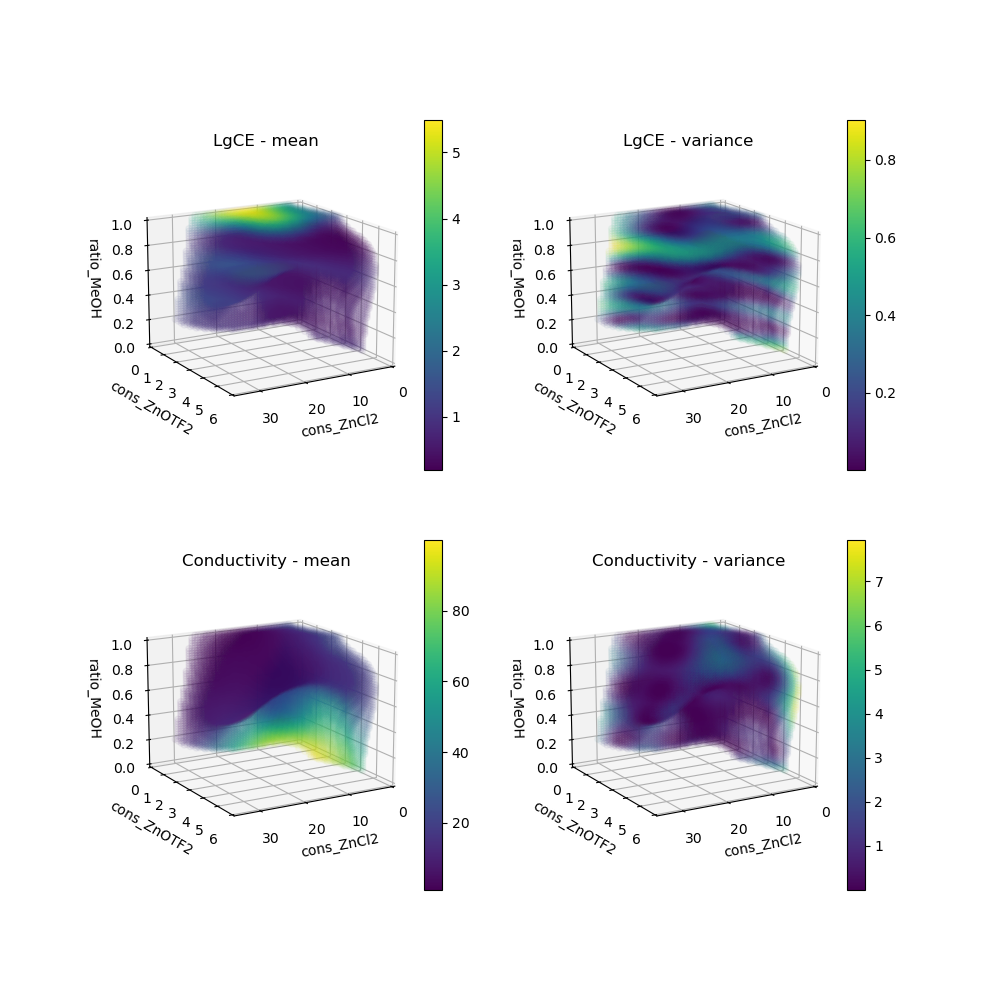

In [6]:
f_preds = model(to_torch(low_res_X), to_torch(low_res_X))
# y_preds = model.likelihood(*f_preds)
y_preds = f_preds


plt.close('all')
fig, axs = plt.subplots(2, 2, subplot_kw=dict(projection='3d'), figsize=(10, 10))

for axr, slice_i, ylabel, scaler in [
    (axs[0], 0, 'LgCE',         lce_scaler),
    (axs[1], 1, 'Conductivity', con_scaler),
]:
    for ax, val_type in [(axr[0], 'mean'), (axr[1], 'variance'), ]:
        vals = getattr(y_preds[slice_i], val_type).detach().numpy()
        if val_type == 'mean':
            vals = scaler.inverse_transform(vals.reshape(-1, 1)).reshape(-1)
        elif val_type == 'variance':
            vals = vals * scaler.scale_[0]
        sc = ax.scatter(*(low_res_X * X_LIMS).T, c=vals, alpha=0.05)
        cbar = plt.colorbar(sc, ax=ax)
        cbar.solids.set(alpha=1)
        
        [getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS)]
        [getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_LIMS)]
        ax.view_init(15, 60)

        ax.set_title(f'{ylabel} - {val_type}')

## 2. Define acquisition functions constrained by conductivity

In [7]:
dtype = torch.double

def get_aqcf(model, data_df, cond_cutoff, constraint='high_conductivity', mc_sample=4096, seed=None):
    set_seed(seed)
    qmc_sampler = SobolQMCNormalSampler(sample_shape=torch.Size([mc_sample]))
 
    if constraint == 'high_conductivity':
        current_f = to_torch(np.where(data_df['Scaled_Conductivity_Mean'].values >= cond_cutoff, data_df['Scaled_LgCE_Mean'].values, -np.inf))
    elif constraint == 'low_conductivity':
        current_f = to_torch(np.where(data_df['Scaled_Conductivity_Mean'].values < cond_cutoff, data_df['Scaled_LgCE_Mean'].values, -np.inf))
    else:
        raise ValueError(f'Unknown aqcf constraint: {constraint}')
    
    linear_obj = LinearMCObjective(torch.tensor([1.0, 0.0], dtype=dtype))

    qEI = qExpectedImprovement(
        model=model,
        objective=linear_obj,
        best_f=current_f.to(dtype).max(),
        sampler=qmc_sampler,
    )
    
    return qEI

hi_qEI = get_aqcf(model, data_df, cond_cutoff, constraint='high_conductivity', seed=RANDOM_SEED)
lo_qEI = get_aqcf(model, data_df, cond_cutoff, constraint='low_conductivity', seed=RANDOM_SEED)

## 3. Run Bayesian Optimization with solubility constraint


In [8]:
import copy
from scipy.spatial.distance import pdist, cdist, squareform
from tqdm.auto import tqdm

class BatchAcqOptimizer:
    def __init__(self, n_comps=6, n_iters=500000, comp_gen_func=None, random_state=None,
                 boltzmann_const=1e5, acq_function=None, cols=None, cache_factor=128,
                 **kwargs):
        self.q = n_comps
        self.n_iters = n_iters
        self.random_state = random_state
        self.comp_gen_func = comp_gen_func
        self.acq_function = acq_function
        self.cache_factor = cache_factor
            
        self.boltzmann_const = boltzmann_const
        self.column_names = cols
        self.kwargs = kwargs

    def _get_rand_comp(self):
        ''' return a random composition '''

        # If the cache does not exist, or the cache is empty, rebuild cache
        if len(getattr(self, '_comp_cache', [])) == 0:
            self._build_comp_cache()

        # pop one composition, and with its prediction if existed, from cache
        comp = self._comp_cache.pop()
        return comp

    def _build_comp_cache(self):
        ''' build cache containing a list of random composition '''
        
        comps = None
        if comps is None:
            seed = self.rng_.integers(0, np.iinfo(np.int64).max)
            comps = self.comp_gen_func(n=self.q * self.cache_factor, random_state=seed, **self.kwargs)
        self._comp_cache = [c for c in comps]
        
    
    def optimize(self):
        pbar = tqdm(total=self.n_iters)

        # Initialize comps and calculate its score
        if not hasattr(self, 'iter_'):
            self.best_score_ = -np.inf
            self.current_score_ = -np.inf
            self.opt_history_ = []
            self.iter_ = 0
            self.rng_ = np.random.default_rng(self.random_state)
            self.current_comps_ = [self._get_rand_comp() for _ in range(self.q)]
        else:
            pbar.update(self.iter_)

        while self.iter_ < self.n_iters:
            self.iter_ += 1
            pbar.update(1)
            pivot = self.rng_.integers(0, len(self.current_comps_))
            
            comps = copy.deepcopy(self.current_comps_)
            new_comp = self._get_rand_comp()
            comps[pivot] = new_comp
            score = self.acq_function(comps)

            # if score > self.best_score_:
            if self.boltzmann_const * (score - self.current_score_) >= np.log(self.rng_.random() ** 0.5):
                self.current_score_ = score
                self.current_comps_ = comps
                self.opt_history_.append([self.iter_, pivot, score])

                if score > self.best_score_:
                    self.best_comps_ = comps
                    self.best_score_ = score
        pbar.close()
        return pd.DataFrame(self.best_comps_, columns=self.column_names)


def conductivity_constraint(comps, cutoff, direction='high'):
    X = to_torch(comps / X_LIMS).to(dtype)
    conductivity = model(X, X)[1].mean.detach().numpy()
    conductivity = con_scaler.inverse_transform(conductivity.reshape(-1, 1)).reshape(-1)
    if direction == 'high':
        return conductivity >= cutoff
    elif direction == 'low':
        return conductivity <= cutoff
    else:
        raise ValueError(f'Unknown direction: {direction}')


common_kwargs = dict(
    cols=X_COLS,
    n_iters=200000,
    boltzmann_const=1.0,
    random_state=0,
    comp_gen_func=get_rand_comp,
    func_kw=dict(kdtree=kdtree, min_dist=0.01, min_comp=0.05, max_comp=0.99, svm_models=svm_models),
    batch_factor=64
)


hi_o = BatchAcqOptimizer(
    n_comps=8,
    acq_function=lambda x: hi_qEI(to_torch(np.array(x)/X_LIMS)).detach().cpu().numpy()[0],
    extra_filter=lambda x: conductivity_constraint(x, 10.0, direction='high'), 
    **common_kwargs
)
hi_df = hi_o.optimize()

lo_o = BatchAcqOptimizer(
    n_comps=4,
    acq_function=lambda x: lo_qEI(to_torch(np.array(x)/X_LIMS)).detach().cpu().numpy()[0],
    extra_filter=lambda x: conductivity_constraint(x, 10.0, direction='low'),
    **common_kwargs
)
lo_df = lo_o.optimize()


  0%|          | 0/200000 [00:00<?, ?it/s]

  0%|          | 0/200000 [00:00<?, ?it/s]

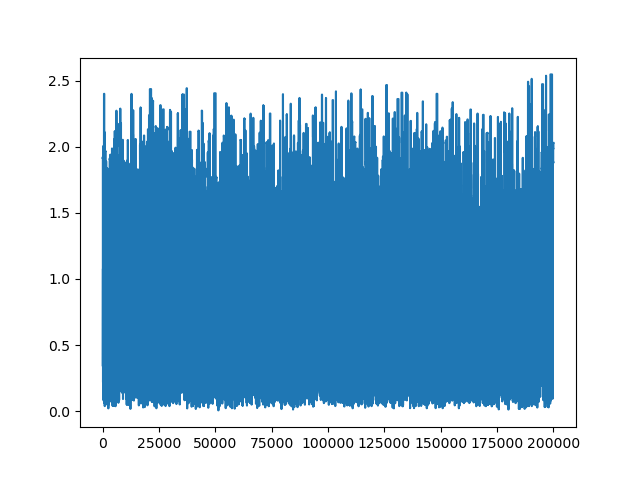

,cons_ZnCl2,cons_ZnOTF2,ratio_MeOH,Pred_LgCE,Pred_CE,Pred_LgCE_Var,Pred_Conductivity,Pred_Conductivity_Var
0,2.80,2.44,0.21,0.493681,67.913773,0.181638,73.745240,0.922122
1,5.36,0.87,0.36,0.567702,72.941839,0.041757,46.077623,0.693889
2,10.74,2.88,0.75,0.635861,76.871950,0.376165,4.839503,2.138561
3,5.88,0.59,0.26,0.644401,77.322288,0.184300,59.269914,0.765513
4,11.04,2.33,0.84,0.650296,77.628056,0.362138,4.911237,1.971134
5,9.00,0.43,0.32,0.748953,82.174292,0.041940,40.912087,0.312057
6,5.15,1.31,0.64,0.894987,87.264578,0.100487,28.685479,1.133204
7,17.28,0.71,0.50,0.923237,88.066629,0.154288,11.762662,0.445758
8,23.12,0.44,0.27,1.201660,93.714499,0.423184,12.862723,0.832064
9,14.51,1.54,0.56,1.276736,94.712337,0.150292,8.356573,0.300631


In [9]:
plt.close('all')
plt.plot(*np.array(hi_o.opt_history_)[:, [0, 2]].T)
plt.show()

X_COLS2 = ['cons_ZnCl2', 'cons_ZnOTF2', 'ratio_MeOH']

def gen_pred_df(candidates):
    X = to_torch(candidates)
    y_preds = model(X, X)
    # y_preds = model.likelihood(*f_preds)
    df = pd.DataFrame(candidates * X_LIMS, columns=X_COLS2)
    df['Pred_LgCE'] = lce_scaler.inverse_transform(y_preds[0].mean.detach().numpy().reshape(-1, 1)).reshape(-1)
    df['Pred_CE'] = inv_ce_log(df['Pred_LgCE'].values)
    df['Pred_LgCE_Var'] = lce_scaler.scale_[0] * y_preds[0].variance.detach().numpy()
    df['Pred_Conductivity'] = con_scaler.inverse_transform(y_preds[1].mean.detach().numpy().reshape(-1, 1)).reshape(-1)
    df['Pred_Conductivity_Var'] = con_scaler.scale_[0] * y_preds[1].variance.detach().numpy()
    return df

batch_df = gen_pred_df(pd.concat([lo_df, hi_df], ignore_index=True).values / X_LIMS).sort_values('Pred_LgCE', ignore_index=True)
batch_df.to_csv(f'AL_03.seed_{RANDOM_SEED}.csv', index=False)
batch_df

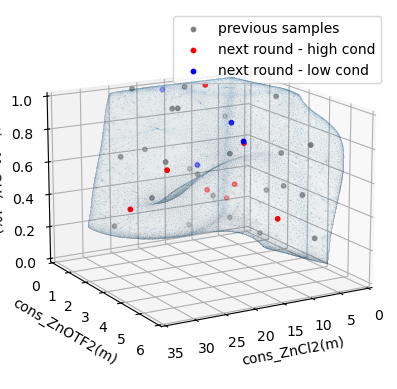

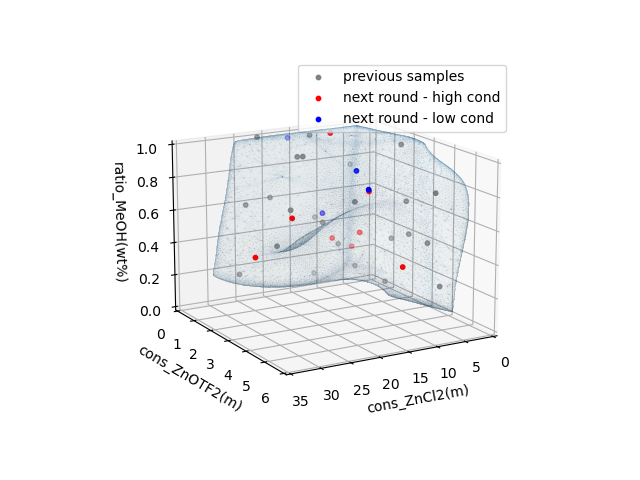

In [10]:
plt.close('all')
fig, ax = plt.subplots(1, 1, subplot_kw=dict(projection='3d'))
ax.plot_trisurf(*(smooth_verts * X_LIMS).T, triangles=smooth_faces, linewidth=0, 
                antialiased=False, alpha=0.02, color='tab:blue')

X_COLS = ['cons_ZnCl2(m)', 'cons_ZnOTF2(m)', 'ratio_MeOH(wt%)']

ax.scatter(*data_df[X_COLS].values.T, s=10, color='grey', label='previous samples')
ax.scatter(*(batch_df[batch_df.Pred_Conductivity >= 10.0][X_COLS2].values).T, s=10, color='red', label='next round - high cond')
ax.scatter(*(batch_df[batch_df.Pred_Conductivity < 10.0][X_COLS2].values).T, s=10, color='blue', label='next round - low cond')

[getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS)]
[getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_LIMS)]
ax.view_init(15, 60)
ax.legend(loc='upper right')
fig
# fig.show()

In [11]:
from matal.vis import marching_cubes, skimg_tri_to_poly, poly_to_skimg_tri, smooth_pvs_poly, get_mesh_pred


X_COLS = ['cons_ZnCl2', 'cons_ZnOTF2', 'ratio_MeOH']
X_LIMS = np.array([35.0, 6.0, 1.0])

margin = 0.05
n_points = 331
pred_sol, grid_space, flattened = get_mesh_pred(svm_models['solubility'], margin=margin, n_points=n_points, target='pred')
pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=margin, n_points=n_points, target='pred', margin_value=-5.0)
pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=margin, n_points=n_points, target='pred', margin_value= 5.0)

# Value cutoff 
oer_cutoff = 1.74
her_cutoff = -0.86

# mask = (flattened[:,0] >= (15 / 35.0)) & (flattened[:,2] < (0.8 / 1.0)) & (flattened[:,2] > (0.25 / 1.0))

mask = (
    (flattened[:,0] >= (15 / 35.0)) & \
    (flattened[:,1] >= (0.5 / 6.0)) & \
    ((flattened[:,0] + flattened[:,1]) >= 0.6) & \
    (flattened[:,2] < (0.8 / 1.0)) & \
    (flattened[:,2] > (0.25 / 1.0))
)

mask = mask.reshape(pred_sol.shape)

merge_pred = ((pred_sol >= 0.5) & (pred_oer >= oer_cutoff) & (pred_her >= her_cutoff)) #.astype(np.float16)
merge_pred = (merge_pred & mask).astype(np.float16)

verts, faces, *_ = marching_cubes(merge_pred, 0.5, spacing=(grid_space, ) * 3, gradient_direction='ascent', allow_degenerate=False)
verts -= margin

# Smooth iso-plane
poly = skimg_tri_to_poly(verts, faces)
smooth_poly2 = smooth_pvs_poly(poly, sm_iters=500, sm_rlx=0.2, sm2_iters=50, sm2_rlx=0.05, dp_factor=0.99, dp_angle=120, dp_iters=100)
smooth_verts2, smooth_faces2 = poly_to_skimg_tri(smooth_poly2)
print(f'Num of edge points:', len(smooth_verts2))


Num of edge points: 930


In [12]:
norm = smooth_poly2.face_normals
m = (norm[:,0] > 0) & (norm[:,1] > 0) & (norm[:,2] > 0.2) & (norm[:,2] < 0.8)
faces = smooth_faces2[m]

vert_points = pd.DataFrame(np.array(smooth_verts2[np.sort(np.unique(faces.reshape(-1)))]) * X_LIMS,
             columns=X_COLS)
vert_points

,cons_ZnCl2,cons_ZnOTF2,ratio_MeOH
0,15.638412,2.518148,0.767648
1,15.620307,2.556113,0.750334
2,15.635819,2.481856,0.776958
3,15.911138,2.503382,0.752246
4,16.116205,2.361889,0.778549
...,...,...,...
125,24.832638,0.582311,0.488166
126,24.927984,0.602410,0.479104
127,25.146090,0.585590,0.418886
128,25.015215,0.581518,0.436822


In [13]:
from scipy.spatial import cKDTree
import pickle
from tqdm.auto import tqdm
import gc

max_iter = 10
max_dist = 0.05

xs = vert_points.values / X_LIMS

auto_log(f'00: {len(xs) = }')
last_size = len(xs)
masks = []
for i in range(1, max_iter):
    d, idx = cKDTree(xs).query(xs, k=2)
    min_idx = idx.min(1)
    mask = d[:,1] > max_dist
    mask[min_idx[~mask]] = True
    xs = xs[mask]
    auto_log(f'{i:02d}: {len(xs) = }')
    if last_size == len(xs):
        break
    masks.append(mask)
    last_size = len(xs)

xs = vert_points.values / X_LIMS
for mi, m in enumerate(masks):
    xs = xs[m]
    print(mi, len(xs))

vert_points2 = pd.DataFrame(xs * X_LIMS, columns=X_COLS)
vert_points2.to_csv('AL_03.seed_0.pareto_front.csv', index=False)
vert_points2

2026-11-27 16:48:21,640 - INFO - [3907981860.py -> <module>] 00: len(xs) = 130
2026-11-27 16:48:21,642 - INFO - [3907981860.py -> <module>] 01: len(xs) = 83
2026-11-27 16:48:21,642 - INFO - [3907981860.py -> <module>] 02: len(xs) = 56
2026-11-27 16:48:21,643 - INFO - [3907981860.py -> <module>] 03: len(xs) = 43
2026-11-27 16:48:21,643 - INFO - [3907981860.py -> <module>] 04: len(xs) = 34
2026-11-27 16:48:21,644 - INFO - [3907981860.py -> <module>] 05: len(xs) = 26
2026-11-27 16:48:21,644 - INFO - [3907981860.py -> <module>] 06: len(xs) = 21
2026-11-27 16:48:21,644 - INFO - [3907981860.py -> <module>] 07: len(xs) = 18
2026-11-27 16:48:21,644 - INFO - [3907981860.py -> <module>] 08: len(xs) = 18
0 83
1 56
2 43
3 34
4 26
5 21
6 18


,cons_ZnCl2,cons_ZnOTF2,ratio_MeOH
0,15.638412,2.518148,0.767648
1,16.679260,2.037870,0.788053
2,18.005281,2.237918,0.596819
3,18.156061,1.591033,0.770646
4,19.568868,1.819813,0.640868
5,19.899091,1.318996,0.718967
6,19.768543,2.071670,0.537847
7,20.300894,0.790998,0.780314
8,21.472917,1.435203,0.588655
9,22.060422,0.742373,0.701247


In [14]:
df2 = (vert_points2 * np.array([[0.99, 0.99, 1.0]])).round(4)
for model_name, model in svm_models.items():
    df2[model_name] = model.predict(df2[X_COLS].values / X_LIMS).round(4)
df2['HER_Flag'] = df2['HER'] >= her_cutoff
df2['OER_Flag'] = df2['OER'] >= her_cutoff
df2.to_csv('AL_03.seed_0.pareto_front.scaled_0.99.csv', index=False)
df2

/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


,cons_ZnCl2,cons_ZnOTF2,ratio_MeOH,solubility,HER,OER,HER_Flag,OER_Flag
0,15.4820,2.4930,0.7676,1,-0.6404,1.9605,True,True
1,16.5125,2.0175,0.7881,1,-0.6460,1.9741,True,True
2,17.8252,2.2155,0.5968,1,-0.6305,1.8904,True,True
3,17.9745,1.5751,0.7706,1,-0.6484,1.9690,True,True
4,19.3732,1.8016,0.6409,1,-0.6351,1.9087,True,True
5,19.7001,1.3058,0.7190,1,-0.6473,1.9467,True,True
6,19.5709,2.0510,0.5378,1,-0.6284,1.8579,True,True
7,20.0979,0.7831,0.7803,1,-0.6598,1.9660,True,True
8,21.2582,1.4209,0.5887,1,-0.6400,1.8855,True,True
9,21.8398,0.7349,0.7012,1,-0.6568,1.9343,True,True


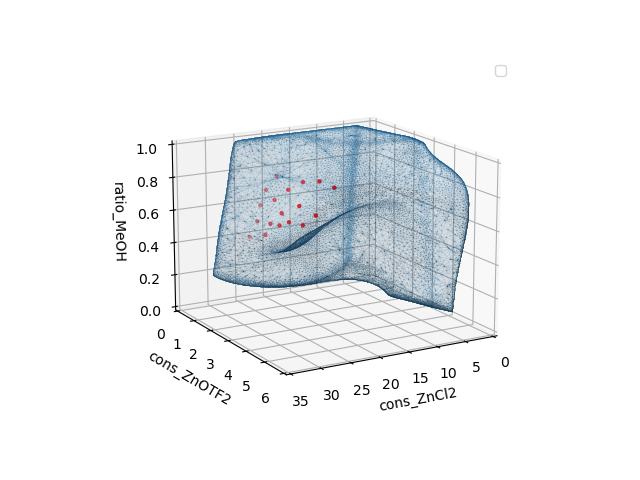

In [15]:
plt.close('all')
fig, ax = plt.subplots(1, 1, subplot_kw=dict(projection='3d'))
# ax.plot_trisurf(*(smooth_verts2 * X_LIMS).T, triangles=faces, linewidth=0, 
#                 antialiased=False, alpha=0.05, color='tab:blue')
ax.plot_trisurf(*(smooth_verts * X_LIMS).T, triangles=smooth_faces, linewidth=1, 
                antialiased=False, alpha=0.08, color='tab:blue')

# ax.scatter(*vert_points.values.T, color='b', s=1, alpha=0.5)
ax.scatter(*vert_points2.values.T, color='r', s=5)
[getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS)]
[getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_LIMS)]
ax.view_init(15, 60)
ax.legend(loc='upper right')
# fig
# fig.show()